# 02 - Data Quality Check
Goal: detect missing values, duplicate rows, and suspicious values.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/airbnb_master_raw.csv")
df = df.drop(columns=["Unnamed: 0"])
print(df.shape)

(51707, 21)


## Step 1: Missing values

In [2]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

pd.DataFrame({"missing_count": missing, "missing_percent": missing_pct})

,missing_count,missing_percent
realSum,0,0.0
room_type,0,0.0
room_shared,0,0.0
room_private,0,0.0
person_capacity,0,0.0
host_is_superhost,0,0.0
multi,0,0.0
biz,0,0.0
cleanliness_rating,0,0.0
guest_satisfaction_overall,0,0.0


## Step 2: Duplicate rows

In [3]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## Step 3: Summary statistics

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
realSum,51707.0,279.879591,327.948386,34.779339,148.752174,211.343089,319.694287,18545.450285
person_capacity,51707.0,3.161661,1.298545,2.000000,2.000000,3.000000,4.000000,6.000000
multi,51707.0,0.291353,0.454390,0.000000,0.000000,0.000000,1.000000,1.000000
biz,51707.0,0.350204,0.477038,0.000000,0.000000,0.000000,1.000000,1.000000
cleanliness_rating,51707.0,9.390624,0.954868,2.000000,9.000000,10.000000,10.000000,10.000000
guest_satisfaction_overall,51707.0,92.628232,8.945531,20.000000,90.000000,95.000000,99.000000,100.000000
bedrooms,51707.0,1.158760,0.627410,0.000000,1.000000,1.000000,1.000000,10.000000
dist,51707.0,3.191285,2.393803,0.015045,1.453142,2.613538,4.263077,25.284557
metro_dist,51707.0,0.681540,0.858023,0.002301,0.248480,0.413269,0.737840,14.273577
attr_index,51707.0,294.204105,224.754123,15.152201,136.797385,234.331748,385.756381,4513.563486


## Step 4: Investigate price outliers

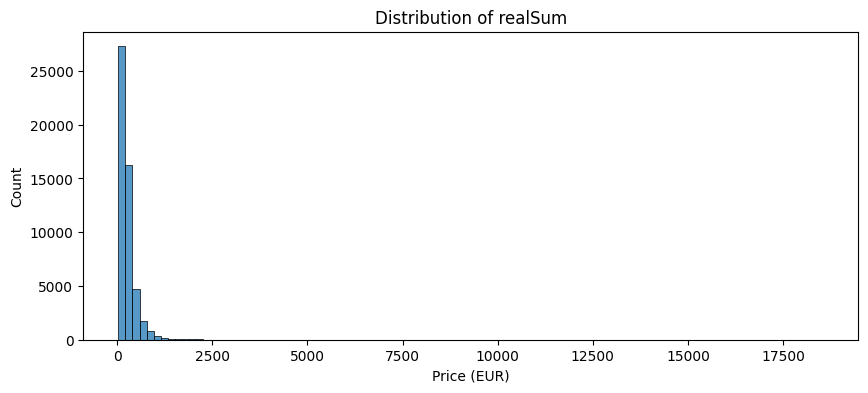

In [6]:
plt.figure(figsize=(10, 4))
sns.histplot(df["realSum"], bins=100)
plt.title("Distribution of realSum")
plt.xlabel("Price (EUR)")
plt.show()

In [7]:
df.nlargest(10, "realSum")[["realSum", "city", "day_type", "room_type", "bedrooms", "person_capacity"]]

,realSum,city,day_type,room_type,bedrooms,person_capacity
3590,18545.450285,Athens,weekdays,Entire home/apt,1,2.0
34803,16445.614689,Paris,weekdays,Entire home/apt,1,2.0
24348,15499.894165,London,weekdays,Entire home/apt,3,3.0
48380,13664.305916,Vienna,weekdays,Private room,1,2.0
50787,13656.358834,Vienna,weekends,Private room,1,2.0
48215,12942.991375,Vienna,weekdays,Entire home/apt,1,4.0
30626,12937.275101,London,weekends,Entire home/apt,2,6.0
31635,12929.513864,London,weekends,Private room,1,2.0
25629,12886.239093,London,weekdays,Entire home/apt,2,6.0
25945,12886.239093,London,weekdays,Private room,1,2.0


In [8]:
Q1 = df["realSum"].quantile(0.25)
Q3 = df["realSum"].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR

outliers = df[df["realSum"] > upper_limit]
print(f"Upper limit: {upper_limit:.2f}")
print(f"Outliers: {len(outliers)} rows ({len(outliers) / len(df) * 100:.2f}%)")

Upper limit: 576.11
Outliers: 3662 rows (7.08%)


## Step 5: Prices by city
A single IQR threshold mixes cheap and expensive cities, so we compare each listing to its own city.

In [9]:
df.groupby("city")["realSum"].median().sort_values()

city
Athens       127.715417
Budapest     152.982093
Rome         182.591822
Berlin       191.175096
Barcelona    208.299393
Vienna       208.494028
Lisbon       225.375235
London       261.294950
Paris        317.597167
Amsterdam    460.244183
Name: realSum, dtype: float64

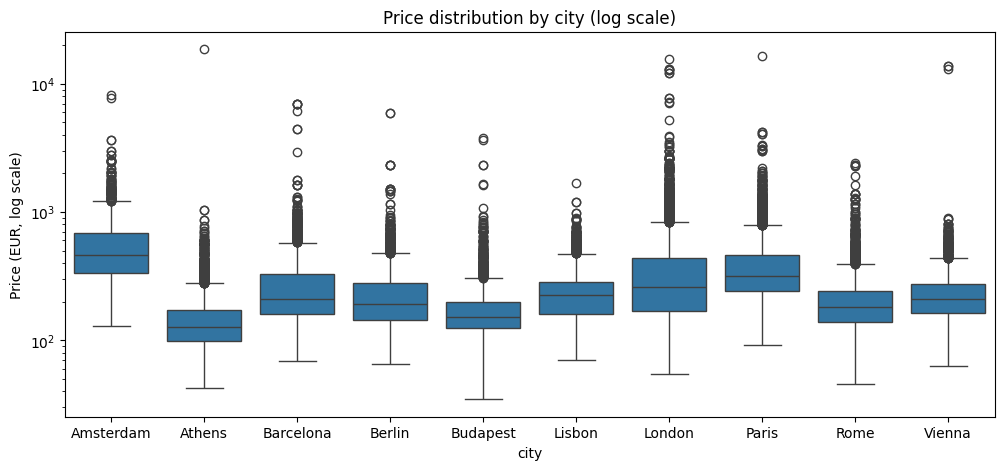

In [10]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="city", y="realSum")
plt.yscale("log")
plt.title("Price distribution by city (log scale)")
plt.ylabel("Price (EUR, log scale)")
plt.show()

In [11]:
df["price_vs_city_median"] = df["realSum"] / df.groupby("city")["realSum"].transform("median")

df.nlargest(15, "price_vs_city_median")[
    ["realSum", "city", "room_type", "bedrooms", "person_capacity", "price_vs_city_median"]
]

,realSum,city,room_type,bedrooms,person_capacity,price_vs_city_median
3590,18545.450285,Athens,Entire home/apt,1,2.0,145.209174
48380,13664.305916,Vienna,Private room,1,2.0,65.538117
50787,13656.358834,Vienna,Private room,1,2.0,65.500000
48215,12942.991375,Vienna,Entire home/apt,1,4.0,62.078475
24348,15499.894165,London,Entire home/apt,3,3.0,59.319532
34803,16445.614689,Paris,Entire home/apt,1,2.0,51.781365
30626,12937.275101,London,Entire home/apt,2,6.0,49.512151
31635,12929.513864,London,Private room,1,2.0,49.482448
25629,12886.239093,London,Entire home/apt,2,6.0,49.316832
25945,12886.239093,London,Private room,1,2.0,49.316832


## Step 6: Choosing an outlier threshold
How many listings would be removed at different "times the city median" thresholds?

In [12]:
for t in [5, 10, 15, 20, 30, 50]:
    n = (df["price_vs_city_median"] > t).sum()
    print(f"> {t:>2}x city median: {n:>4} rows ({n / len(df) * 100:.3f}%)")

>  5x city median:  313 rows (0.605%)
> 10x city median:   72 rows (0.139%)
> 15x city median:   32 rows (0.062%)
> 20x city median:   27 rows (0.052%)
> 30x city median:   18 rows (0.035%)
> 50x city median:    6 rows (0.012%)


In [14]:
df[(df["price_vs_city_median"] > 20) & (df["price_vs_city_median"] <= 30)][
    ["realSum", "city", "room_type", "bedrooms", "person_capacity", "price_vs_city_median"]
].sort_values("price_vs_city_median")

,realSum,city,room_type,bedrooms,person_capacity,price_vs_city_median
8708,4467.149208,Barcelona,Entire home/apt,6,6.0,21.445810
10034,4467.149208,Barcelona,Entire home/apt,6,6.0,21.445810
14615,3630.681017,Budapest,Entire home/apt,1,3.0,23.732719
16057,3751.233727,Budapest,Entire home/apt,1,3.0,24.520737
32081,7115.642419,London,Entire home/apt,3,3.0,27.232223
25996,7223.829347,London,Entire home/apt,2,4.0,27.646265
9409,6086.298787,Barcelona,Entire home/apt,3,2.0,29.218994
26584,7759.354641,London,Entire home/apt,3,6.0,29.695770
31185,7759.354641,London,Entire home/apt,3,6.0,29.695770


### Decision: outlier threshold = 30x city median
- Listings priced above 30x their city's median price will be removed during cleaning (18 rows, 0.035%).
- Above 30x, almost all listings are implausible (e.g. private rooms for 2 people priced over EUR 12,000).
- Between 20x and 30x the listings are mixed (some large luxury homes, some suspicious), so they are kept.
- Because some extreme values remain, the analysis will use the **median** price rather than the mean.

## Step 7: Correlation between price and numeric features
Computed after excluding the extreme outliers (> 30x city median), since a few extreme values can distort correlation.

In [15]:
df_check = df[df["price_vs_city_median"] <= 30].drop(columns=["price_vs_city_median"])

corr = (
    df_check.select_dtypes(include=["number", "bool"])
    .astype(float)
    .corr()["realSum"]
    .drop("realSum")
    .sort_values()
)
corr

lng                          -0.232902
room_private                 -0.232338
metro_dist                   -0.077848
multi                        -0.061108
host_is_superhost            -0.060084
dist                         -0.059968
room_shared                  -0.045964
guest_satisfaction_overall   -0.000927
cleanliness_rating            0.000797
biz                           0.047822
rest_index                    0.183100
rest_index_norm               0.198456
attr_index                    0.239433
person_capacity               0.276751
lat                           0.278111
bedrooms                      0.287136
attr_index_norm               0.381555
Name: realSum, dtype: float64

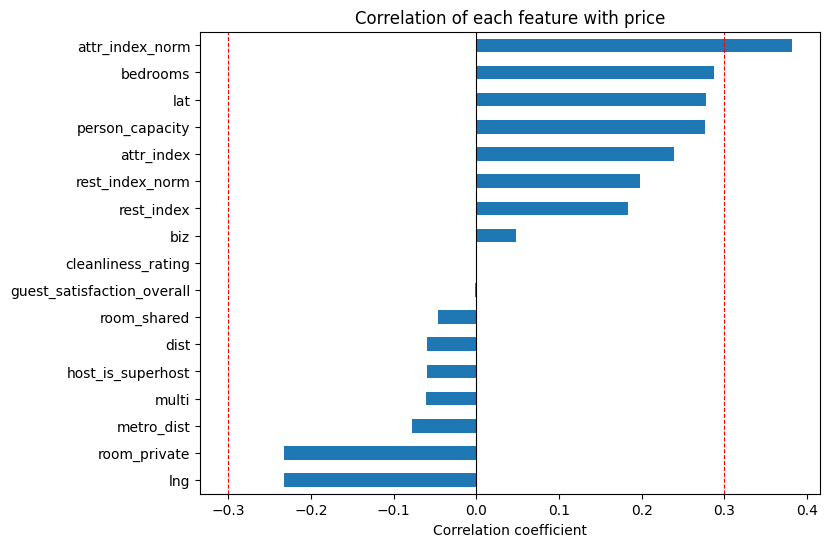

In [16]:
plt.figure(figsize=(8, 6))
corr.plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.axvline(0.3, color="red", linestyle="--", linewidth=0.8)
plt.axvline(-0.3, color="red", linestyle="--", linewidth=0.8)
plt.title("Correlation of each feature with price")
plt.xlabel("Correlation coefficient")
plt.show()

## Conclusions from the data quality check
1. **Missing values:** none in any column.
2. **Duplicate rows:** none.
3. **Price outliers:** prices are strongly right-skewed (mean EUR 280 vs median EUR 211, max EUR 18,545).
   Listings above 30x their city's median (18 rows) are implausible and will be removed during cleaning.
4. **Price differs a lot by city:** median ranges from EUR 128 (Athens) to EUR 460 (Amsterdam), so comparisons should be made per city.
5. **Weak correlations:** only `attr_index_norm` (0.38) exceeds |0.3|; all other features are weakly related to price.
   This matches the project hint and justifies enriching the data with extra features (amenities, reviews, host and property details) through web scraping.